# **CA4 @ AI Spring 2025**
# Convolutional vs. Fully Connected Neural Networks

- **Name: mahdi yari**
- **Student ID: 810102532**

---
Your submission should be named using the following format: `AI_CA4_LASTNAME_STUDENTID.ipynb`.

---

 *How to do this problem set:*

- Some questions require writing Python code and computing results, and the rest of them have written answers. For coding problems, you will have to fill out all code blocks that say `YOUR CODE HERE`.

- For text-based answers, you should replace the text that says `WRITE YOUR ANSWER HERE` with your actual answer.
---
If you have any further questions or concerns, contact the TAs via email or Telegram.

# Introduction
In this assignment, you will compare fully connected neural networks with convolutional neural networks to evaluate whether convolutional architectures offer superior performance—and understand the reasons behind any observed differences.

**Important Note:**

Before you begin, please make sure to review the accompanying PyTorch tutorial provided alongside this file.

## Colab Setup

If you are running this notebook on Google Colab, you can mount your Google Drive using the following code to access or upload files directly from your Drive.

In [1]:
# from google.colab import drive
# import os

# drive.mount('/content/drive')

# GOOGLE_DRIVE_PATH = os.path.join('drive', 'My Drive', 'AIS25-CA4')
# os.chdir(GOOGLE_DRIVE_PATH)

## Device

As demonstrated in the PyTorch tutorial, PyTorch enable you to run your code on GPU to accelerate computations.

In [2]:
import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Dataset

## Transforms & Dataset & Dataloader

Here, you should download and load the dataset with the desire transforms. After that, you should split train dataset to train and validation sets. Finally, define the dataloaders for `train`, `validation` and `test`

In [3]:
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

In [4]:
from torchvision import transforms

transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.491, 0.482, 0.446), (0.247, 0.243, 0.261)),
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.491, 0.482, 0.446), (0.247, 0.243, 0.261)),
])

In [5]:
from torch.utils.data import random_split
from torch.utils.data import DataLoader
import torchvision

batch_size = 512
num_workers = 2

initial_trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform_train)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform_test)

trainset, valset = random_split(initial_trainset, [45000, 5000])
#######################
trainloader = DataLoader(trainset, batch_size = batch_size, shuffle = True, num_workers = num_workers, pin_memory = True)
valloader   = DataLoader(valset, batch_size = batch_size, shuffle = False, num_workers = num_workers, pin_memory = True)
testloader  = DataLoader(testset, batch_size = batch_size, shuffle = False, num_workers = num_workers, pin_memory = True)

100%|██████████| 170M/170M [00:13<00:00, 13.0MB/s]


## Visualization

Visualize 5 random images from each class in different columns

- **Hint**:  You can use `plt.subplots` for visualization

In [6]:
# inverse the normilize transform to restore the original data
import torch

class UnNormalize(object):
    def __init__(self, mean, std):
        self.mean = torch.tensor(mean).view(3, 1, 1)
        self.std = torch.tensor(std).view(3, 1, 1)

    def __call__(self, tensor, gray=False, coeff=(0.3, 0.59, 0.11)):
        """
        Args:
            tensor (Tensor): Tensor image of size (C, H, W) to be unnormalized.
        Returns:
            Tensor: Unnormalized image.
        """
        # YOUR CODE HERE
        return tensor * self.std + self.mean

norminv = UnNormalize(mean=(0.491, 0.482, 0.446), std=(0.247, 0.243, 0.261))

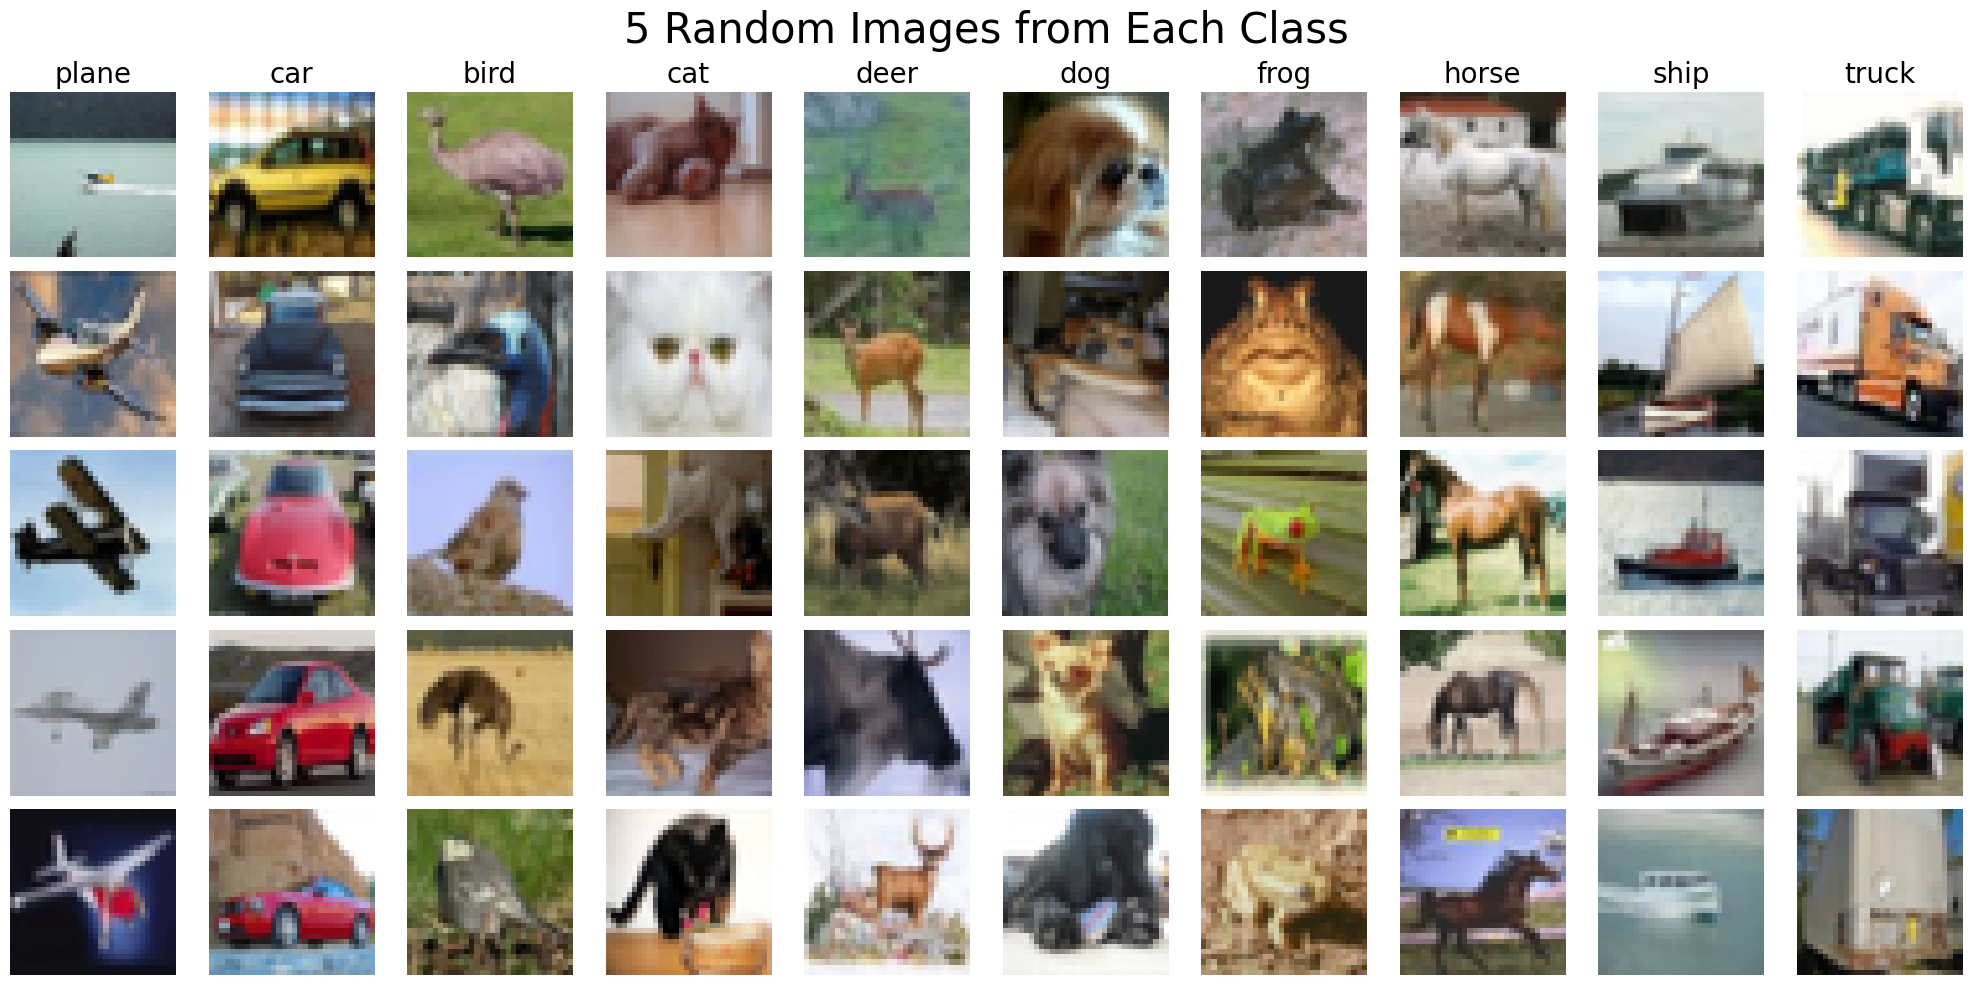

In [7]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import numpy as np
import random

image_list = []
for img, _ in trainset:
    image_list.append(img)
all_images = torch.stack(image_list)
label_list = []
for _, label in trainset:
    label_list.append(label)
all_labels = torch.tensor(label_list)


fig, axes = plt.subplots(5, 10, figsize=(20, 10))
fig.suptitle("5 Random Images from Each Class", fontsize=30)

for class_id in range(10):
    indices = (all_labels == class_id).nonzero(as_tuple=True)[0]
    selected = random.sample(indices.tolist(), 5)
    for i, idx in enumerate(selected):
        img = all_images[idx]
        img = norminv(img)
        img = img.permute(1, 2, 0).numpy()
        ax = axes[i, class_id]
        ax.imshow(img)
        ax.axis('off')
        if i == 0:
            ax.set_title(classes[class_id], fontsize=20)
plt.tight_layout()
plt.show()


# Fully Connected Neural Netwrok

Your first task is to build a fully connected neural network with PyTorch. To achieve this, it is recommended that you familiarize yourself with the following PyTorch components and incorporate them into your network architecture:

* [`nn.Module`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html)
* [`nn.Sequential`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Sequential.html)
* [`nn.Linear`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Linear.html)
* [`nn.ReLU`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ReLU.html)
* [`nn.Dropout`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html)
* [`nn.Flatten`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Flatten.html)

In the provided template below, the final layer of the model should be defined separately and assigned the name `linear`, as it will be referenced in a later section of this assignment.

To ensure a fair comparison with convolutional neural networks (CNNs), both models should have approximately the same number of trainable parameters. Specifically, the fully connected model should contain **33,500,000 ± 500,000** trainable parameters.

You will calculate the exact number of trainable parameters in the following subsection to ensure this requirement is met.




In [8]:
import torch
import numpy as np
import torchvision
import torch.nn as nn
import math
from torchvision import transforms

class FullyConnectedNetwork(nn.Module):
    def __init__(self, input_shape=(3, 32, 32), num_classes=10):
        super(FullyConnectedNetwork, self).__init__()
        # YOUR CODE HERE
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 3400),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(3400, 3400),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(3400, 3400),
            nn.ReLU(),
            nn.Dropout(0.5),
        )
        self.linear = nn.Linear(3400, num_classes)

    def forward(self, x):
        # YOUR CODE HERE
        x = self.model(x)
        x = self.linear(x)
        return x




## Trainable params

Based on the defined architecture, manually calculate the total number of trainable parameters:

## Trainable Parameters Calculation
- input is 3*32*32 = 3072
- Linear(3072 -> 3400): 3072 * 3400 + 3400 = 10448200
- Linear(3400 -> 3400): 3400 * 3400 + 3400 = 11563400
- Linear(3400 -> 3400): 3400 * 3400 + 3400 = 11563400
- Linear(3400 -> 10): 3400 * 10 + 10 = 34010
- 10448200 + 11563400 + 11563400 + 34010 = 33609010



Once you have completed your hand calculation, you can verify your result by running the following cell:

In [9]:
from torchsummary import summary
summary(FullyConnectedNetwork().to(device), input_size=(3, 32, 32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
           Flatten-1                 [-1, 3072]               0
            Linear-2                 [-1, 3400]      10,448,200
              ReLU-3                 [-1, 3400]               0
           Dropout-4                 [-1, 3400]               0
            Linear-5                 [-1, 3400]      11,563,400
              ReLU-6                 [-1, 3400]               0
           Dropout-7                 [-1, 3400]               0
            Linear-8                 [-1, 3400]      11,563,400
              ReLU-9                 [-1, 3400]               0
          Dropout-10                 [-1, 3400]               0
           Linear-11                   [-1, 10]          34,010
Total params: 33,609,010
Trainable params: 33,609,010
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Fo

## Train

### Model Instantiation

Create an instance of your model and move it to your selected device (CPU or GPU). Refer to the PyTorch-tutorial notebook for guidance on how to perform this operation.

In [10]:
model = None
# YOUR CODE HERE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = FullyConnectedNetwork()
model = model.to(device)
model = FullyConnectedNetwork().to(device)
print(f"Model is on: {next(model.parameters()).device}")


Model is on: cuda:0


### Criterion & Optimizer


To train a neural network, we require a **loss function** (referred to as the *criterion*) to quantify the difference between the model's predictions and the true labels. This loss is then used to compute the gradients of the model parameters.

In addition, an **optimization algorithm** is needed to update the model's parameters using the calculated gradients, in order to minimize the loss over time.

You are encouraged to read about the following PyTorch components:

* [`nn.CrossEntropyLoss`](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
* [`torch.optim.Adam`](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

In [11]:
# criterion = None # YOUR CODE HERE
criterion = nn.CrossEntropyLoss()

# optimizer = None # YOUR CODE HERE
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)


### Train loop

Train your model

Tasks:
- Things that are needed to be printed in each epoch:
  - Number of epoch
  - Train loss
  - Train accuracy
  - Validation loss
  - Validation accuracy
- save train/validation loss and accuracy (of each epoch) in an array for later usage

In [12]:
def train_epoch(net: torch.nn.Module, criterion: torch.nn.Module, optimizer: torch.optim.Optimizer ,dataloader: torch.utils.data.DataLoader):
    """
    Trains the neural network for a single epoch.

    Args:
        net (torch.nn.Module): The neural network model to be trained.
        criterion (torch.nn.Module): The loss function used to compute the training loss.
        optimizer (torch.optim.Optimizer): The optimization algorithm used to update model parameters.
        dataloader (torch.utils.data.DataLoader): DataLoader providing the training data in batches.

    Returns:
        tuple:
            - avg_loss (float): The average loss across all batches in the epoch.
            - accuracy (float): The classification accuracy (in percentage) over the entire dataset for the epoch.

    Notes:
        - The `criterion` computes the loss between the model's predictions and the true labels.
        - The `optimizer` updates the model's parameters based on the computed gradients to minimize the loss.
    """
    net.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)
        _, preds = outputs.max(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    avg_loss = running_loss / total
    accuracy = 100. * correct / total
    # YOUR CODE HERE
    return avg_loss, accuracy

def eval_epoch(net: torch.nn.Module, criterion: torch.nn.Module, dataloader: torch.utils.data.DataLoader, test_mode: bool = False):
    """
    Evaluates the neural network on a validation or test dataset for one epoch.
    """
    net.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * inputs.size(0)
            _, preds = outputs.max(1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    avg_loss = running_loss / total
    accuracy = 100. * correct / total
    # YOUR CODE HERE
    return avg_loss, accuracy

As previously mentioned, ensuring a fair comparison between models requires consistency in certain aspects of the training setup. One key factor is the number of **trainable parameters**, and another is the number of times the model processes the entire dataset—referred to as an **epoch**.

To maintain consistency in training duration across models, **do not modify** the `epochs` variable defined below.


In [13]:
epochs = 60 # Do not modify

history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}


for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, criterion, optimizer, trainloader)
    val_loss, val_acc = eval_epoch(model, criterion, valloader)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"(Epoch {epoch + 1} / {epochs}) train loss:{train_loss: .4f}; train acc:{train_acc: .2f}%; val loss:{val_loss: .4f}; val_acc:{val_acc: .2f}%")

(Epoch 1 / 60) train loss: 1.7981; train acc: 35.63%; val loss: 1.5739; val_acc: 44.74%
(Epoch 2 / 60) train loss: 1.6008; train acc: 43.46%; val loss: 1.4887; val_acc: 48.24%
(Epoch 3 / 60) train loss: 1.5206; train acc: 46.22%; val loss: 1.4646; val_acc: 48.86%
(Epoch 4 / 60) train loss: 1.4673; train acc: 48.17%; val loss: 1.4403; val_acc: 49.10%
(Epoch 5 / 60) train loss: 1.4216; train acc: 49.86%; val loss: 1.3965; val_acc: 51.46%
(Epoch 6 / 60) train loss: 1.3878; train acc: 51.19%; val loss: 1.3745; val_acc: 52.00%
(Epoch 7 / 60) train loss: 1.3513; train acc: 52.23%; val loss: 1.3929; val_acc: 51.58%
(Epoch 8 / 60) train loss: 1.3178; train acc: 53.54%; val loss: 1.3675; val_acc: 52.16%
(Epoch 9 / 60) train loss: 1.2845; train acc: 54.47%; val loss: 1.3409; val_acc: 53.08%
(Epoch 10 / 60) train loss: 1.2597; train acc: 55.58%; val loss: 1.3471; val_acc: 52.88%
(Epoch 11 / 60) train loss: 1.2331; train acc: 56.25%; val loss: 1.3368; val_acc: 53.80%
(Epoch 12 / 60) train loss: 1.

### Save Model

Save the trained model for use in subsequent sections to avoid retraining it later.


In [14]:
torch.save(model.state_dict(), "fully-connected.pth")

In [15]:
# To load the previously saved model, simply uncomment the code below.
# model.load_state_dict(torch.load('fully-connected.pth'))

### Visualize Loss and Accuracy plot

Using the arrays that you have (from task 2 in the above section), visualize two plots: Accuracy plot (train and validation together) and Loss plot (train and validation together)

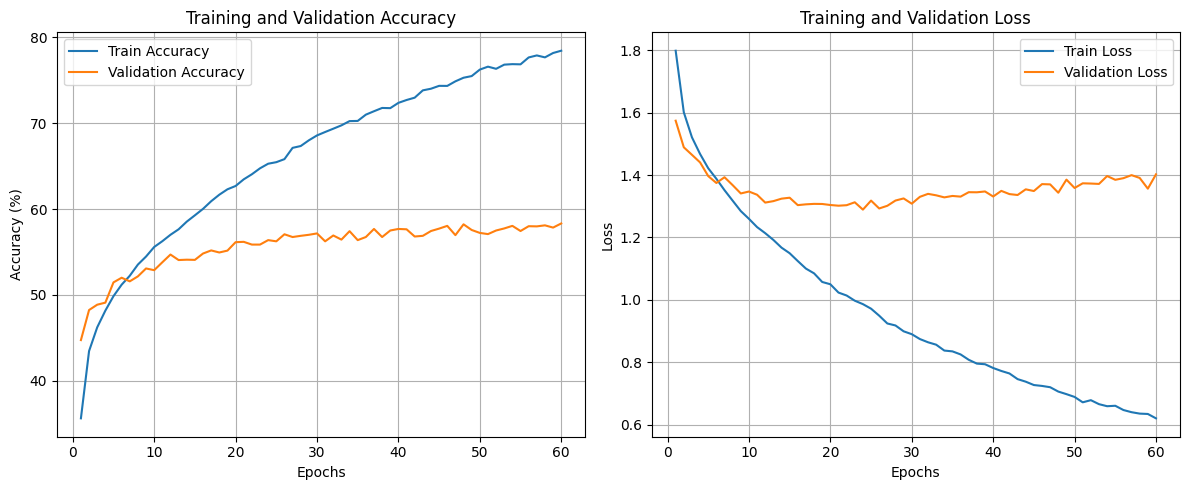

In [16]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
epochs = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_acc'], label='Train Accuracy')
plt.plot(epochs, history['val_acc'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(epochs, history['train_loss'], label='Train Loss')
plt.plot(epochs, history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

به نظر اورفیت رخ داده

چون ترین لوز به مرور کاهش یافته و کمتر از ولیدیشن داره میشه

## Evaluation

Test your trained model (using the Test Dataloader that you have). Our goal is to reach an accuracy above `60%`

In [17]:
# YOUR CODE HERE
test_loss, test_acc = eval_epoch(model, criterion, testloader, test_mode = True)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

Test Loss: 1.3950
Test Accuracy: 57.69%


PROBLEMS:

what is DataLoader?


ما توی کتابخونه پای تورچ برای خواندن داده ها دو راه داریم اینکه یا از دیتاست استفاده کنیم یا از همین دیتا لودر
دیتا ست همون ابزار ابتدایی هست که به ما اجازه دسترسی به تک تک داده هارو با استفاده از اندیسشان میده
ولی دیتالودر یه چیز بهتر از دیتا ست هست و امکانات بیشتری میده بهمون مثلا قابلین شافل کردن و تقسیم داده ها به بچ ها و سرعتش هم بیشتره

Why we use DataLoader?

استفاده مستقیم از دیتاست قط امکان دسترسی به نمونه‌های تکی را می‌دهد. اما در تمرین‌های یادگیری ماشین، معمولاً باید: داده هارو به بچ های کوچکتر تقسیم کرد  و آن هارو در هر شافل اپک کنیم با سرعت بالا، بدون توقف زیاد، در حین آموزش بارگذاری شوند.
دیتالودر اینارو خودکار انجام میده و سریع تر و بهینه تر و استاندارد تر هست

مزایا:

Batching:

به جای خواندن نمونه‌های تکی، داده‌ها را به صورت دسته‌ای بارگذاری می‌کند که برای آموزش شبکه‌های عصبی بسیار ضروری است

Shuffling:

می‌تواند داده‌ها را در هر اپک به صورت تصادفی مرتب کند تا مدل اورفیت نکند

What is Dropout and how does it work?

دراپ اوت یک تکنیک برای جلوگیری از اورفیت هست در زمان ترین در هر مرحله برخی از نورون ها با احتمال مشخص به صورت تصادفی خاموش میشن یعنی مقدار خروجی اونا صفر میشه این باعث میشه که مدل وابستگی کمتری به نورون های خاص پیدا کنه و یاد بگیره که ویژگی هارو به صورت مقاوم تر و پراکنده تر استخراج کنه در زمان تست و ارزیابی، همه نورون‌ها فعال هستند اما وزن‌ها به طور متناسب تنظیم می‌شوند.
این روش باعث افزایش عمومیت مدل و کاهش احتمال یادگیری بیش از حد جزئیات داده‌های آموزش می‌شود

What is CrossEntropy and how does it work?

 یکی از پرکاربردترین توابع هزینه در مسائل طبقه‌بندی چندکلاسه است.

 خروجی شبکه معمولا به صورت برداری از نمرات است که باید به احتمال‌های هر کلاس تبدیل شود.

تابع Softmax احتمال هر کلاس را از نمرات محاسبه می‌کند

CrossEntropy سپس میزان خطا بین احتمال پیش‌بینی‌شده و برچسب واقعی (یک داغ) را محاسبه می‌کند.

این تابع باعث می‌شود مدل تشویق شود که احتمال کلاس درست را افزایش دهد و احتمال کلاس‌های اشتباه را کاهش دهد



What is Adam and how does it work?

یک الگوریتم بهینه‌سازی است که به صورت خودکار نرخ یادگیری را برای هر پارامتر تنظیم می‌کند.

این الگوریتم میانگین متحرک گرادیان‌ها (اولین لحظه) و میانگین متحرک مربع گرادیان‌ها (دومین لحظه) را محاسبه می‌کند.

این دو مقدار برای بهبود روند به‌روزرسانی وزن‌ها به کار می‌روند

معمولا سریع‌تر همگرا می‌شود و به تنظیم دقیق نرخ یادگیری کمتری نیاز دارد.

تفاوتا:

ادم از میانگین‌گیری نمایی برای گرادیان‌ها و مربع گرادیان‌ها استفاده می‌کند، در حالی که اس جی دی فقط از گرادیان فعلی استفاده می‌کند.

ادم برای هر پارامتر نرخ یادگیری جداگانه تنظیم می‌کند، ولی اس جی دی از یک نرخ یادگیری ثابت برای همه پارامترها استفاده می‌کند (مگر اینکه دستی کاهش یابد).

ادم معمولاً سریع‌تر همگرا می‌شود و به تنظیمات حساسیت کمتری دارد، در حالی که اس جی دی نیاز به تنظیم دقیق نرخ یادگیری دارد.

در مسائل پیچیده یا شبکه‌های بزرگ، ادم عملکرد پایدارتر و دقیق‌تری نسبت به اس جی دی دارد.

در مجموع، ادم روش بهینه‌تری برای مسائل پیچیده است، ولی در برخی مسائل ساده یا وقتی داده زیاد باشد، اس جی دی بهتر تعمیم می‌دهد.

# Convolutional Neural Network

## Model

Define your model here from scratch (You are not allowed to use the existing models in pytorch)

**NOTICE:** The model that you will have defined outputs a vector containing 10 numbers (for each class). Define a "feature space" that is a vector of size *N* (where *N > 10*) right before the last layer (You can then have a last layer like `nn.Linear(N, 10)`). See the image below to get a better understanding. We will use this later (we want to access the feature space of a sample when the sample is given to the model). The model tries to learn a representation of the samples in this feature space and we will see how good it could do this in later sections.

![Feature Space In Neural Network](https://i.postimg.cc/28Qjcn9D/feature-space-vis.png)

 You are encouraged to learn about the following core components commonly used in convolutional neural networks:

* [`nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
* [`nn.MaxPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html)

**Reminder**: The model you define should contain 33,500,000 ± 500,000 trainable parameters.

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [19]:
###############
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 128, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(128)

        self.conv2 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(256)

        self.conv3 = nn.Conv2d(256, 512, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(512)

        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(512 * 4 * 4, 3470)
        self.bn_fc1 = nn.BatchNorm1d(3470)

        self.fc2 = nn.Linear(3470, 1024)
        self.bn_fc2 = nn.BatchNorm1d(1024)
        self.fc3 = nn.Linear(1024, num_classes)
        self.extract_features = False

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = F.relu(self.bn_fc1(self.fc1(x)))
        x = self.dropout(x)
        features = F.relu(self.bn_fc2(self.fc2(x)))
        out = self.fc3(features)
        if self.extract_features:
            return out, features
        else:
            return out


## Trainable params

Based on the defined architecture, manually calculate the total number of trainable parameters:

## CNN Trainable Parameters Calculation
- Conv1 (3 = 128, 3×3):  
  (3 × 3 × 3) × 128 + 128 = 3,584
- Conv2 (128 = 256, 3×3):  
  (128 × 3 × 3) × 256 + 256 = 295,168
- Conv3 (256 = 512, 3×3):  
  (256 × 3 × 3) × 512 + 512 = 1,180,160

- After 3 MaxPool layers (stride=2), image size reduces from 32×32 to 4×4.
- Output feature map size: 512 × 4 × 4 = 8192

- FC1 (8192 = 3470):  
  8192 × 3470 + 3470 = 28,437,910
- FC2 (3470 = 1024):  
  3470 × 1024 + 1024 = 3,555,904
- FC3 (1024 = 10):  
  1024 × 10 + 10 = 10,250
### Total Trainable Parameters:
> 33,483,956 parameters
This meets the target range of 33 million ± 0.5 million parameters.


Once you have completed your hand calculation, you can verify your result by running the following cell:

In [20]:


import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from torchsummary import summary
summary(CNN().to(device), input_size=(3, 32, 32))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 128, 32, 32]           3,584
       BatchNorm2d-2          [-1, 128, 32, 32]             256
         MaxPool2d-3          [-1, 128, 16, 16]               0
            Conv2d-4          [-1, 256, 16, 16]         295,168
       BatchNorm2d-5          [-1, 256, 16, 16]             512
         MaxPool2d-6            [-1, 256, 8, 8]               0
            Conv2d-7            [-1, 512, 8, 8]       1,180,160
       BatchNorm2d-8            [-1, 512, 8, 8]           1,024
         MaxPool2d-9            [-1, 512, 4, 4]               0
          Dropout-10                 [-1, 8192]               0
           Linear-11                 [-1, 3470]      28,429,710
      BatchNorm1d-12                 [-1, 3470]           6,940
          Dropout-13                 [-1, 3470]               0
           Linear-14                 [-

## Train

### Model instantiation

Create an instance of your model and move it to `device`

In [21]:
# model = None
# YOUR CODE HERE


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN(num_classes=10).to(device)


### Criterion & Optimizer

Define `criterion` and `optimizer`

In [22]:
# YOUR CODE HERE
import torch.optim as optim

# optimizer = optim.Adam(model.parameters(), lr=0.001)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)
# scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.5)


### Train loop

Train your model

Tasks:
- Things that are needed to be printed in each epoch:
  - Number of epoch
  - Train loss
  - Train accuracy
  - Validation loss
  - Validation accuracy
- save train/validation loss and accuracy (of each epoch) in an array for later usage

In [23]:
epochs = 60 # Do not modify
history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, criterion, optimizer, trainloader)
    val_loss, val_acc = eval_epoch(model, criterion, valloader)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"(Epoch {epoch + 1} / {epochs}) train loss:{train_loss: .4f}; train acc:{train_acc: .2f}%; val loss:{val_loss: .4f}; val_acc:{val_acc: .2f}%")

(Epoch 1 / 60) train loss: 1.2494; train acc: 55.00%; val loss: 1.0579; val_acc: 62.86%
(Epoch 2 / 60) train loss: 0.8631; train acc: 69.33%; val loss: 0.8538; val_acc: 69.28%
(Epoch 3 / 60) train loss: 0.7213; train acc: 74.25%; val loss: 0.6975; val_acc: 75.90%
(Epoch 4 / 60) train loss: 0.6294; train acc: 77.86%; val loss: 0.6800; val_acc: 76.74%
(Epoch 5 / 60) train loss: 0.5586; train acc: 80.21%; val loss: 0.6867; val_acc: 76.66%
(Epoch 6 / 60) train loss: 0.5033; train acc: 82.14%; val loss: 0.6620; val_acc: 77.82%
(Epoch 7 / 60) train loss: 0.4449; train acc: 84.27%; val loss: 0.6291; val_acc: 78.44%
(Epoch 8 / 60) train loss: 0.4063; train acc: 85.48%; val loss: 0.5624; val_acc: 80.48%
(Epoch 9 / 60) train loss: 0.3702; train acc: 86.86%; val loss: 0.5899; val_acc: 80.74%
(Epoch 10 / 60) train loss: 0.3277; train acc: 88.28%; val loss: 0.5423; val_acc: 82.00%
(Epoch 11 / 60) train loss: 0.3026; train acc: 89.25%; val loss: 0.5500; val_acc: 82.30%
(Epoch 12 / 60) train loss: 0.

### Save Model

Since changes need to be made to the model later on, it is advisable to save your model to avoid having to retrain it in case of any issues.

In [24]:
torch.save(model.state_dict(), "cnn.pth")

In [25]:
# To load the previously saved model, simply uncomment the code below.
# model.load_state_dict(torch.load('cnn.pth'))

### Visualize Loss and Accuracy plot

Using the arrays that you have (from task 2 in the above section), visualize two plots: Accuracy plot (train and validation together) and Loss plot (train and validation together)

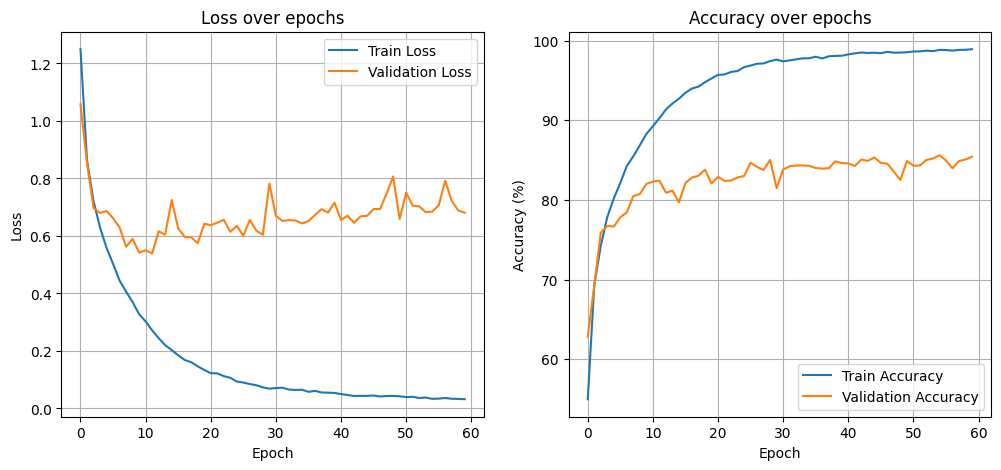

In [26]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.title('Loss over epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Validation Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.show()


## Evaluation

Test your trained model (using the Test Dataloader that you have). Our goal is to reach an accuracy above `80%`

In [37]:
model.eval()
test_loss, test_acc = eval_epoch(model, criterion, testloader, test_mode=True)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

Test Loss: 0.7566
Test Accuracy: 84.45%


## Visualize incorrectly predicted samples from testset

Visualize *24* random images from testset that are incorrectly predicted by the model. Note that if you used normalization in the transform function for loading the data, you will need to unnormalize the images before displaying them.

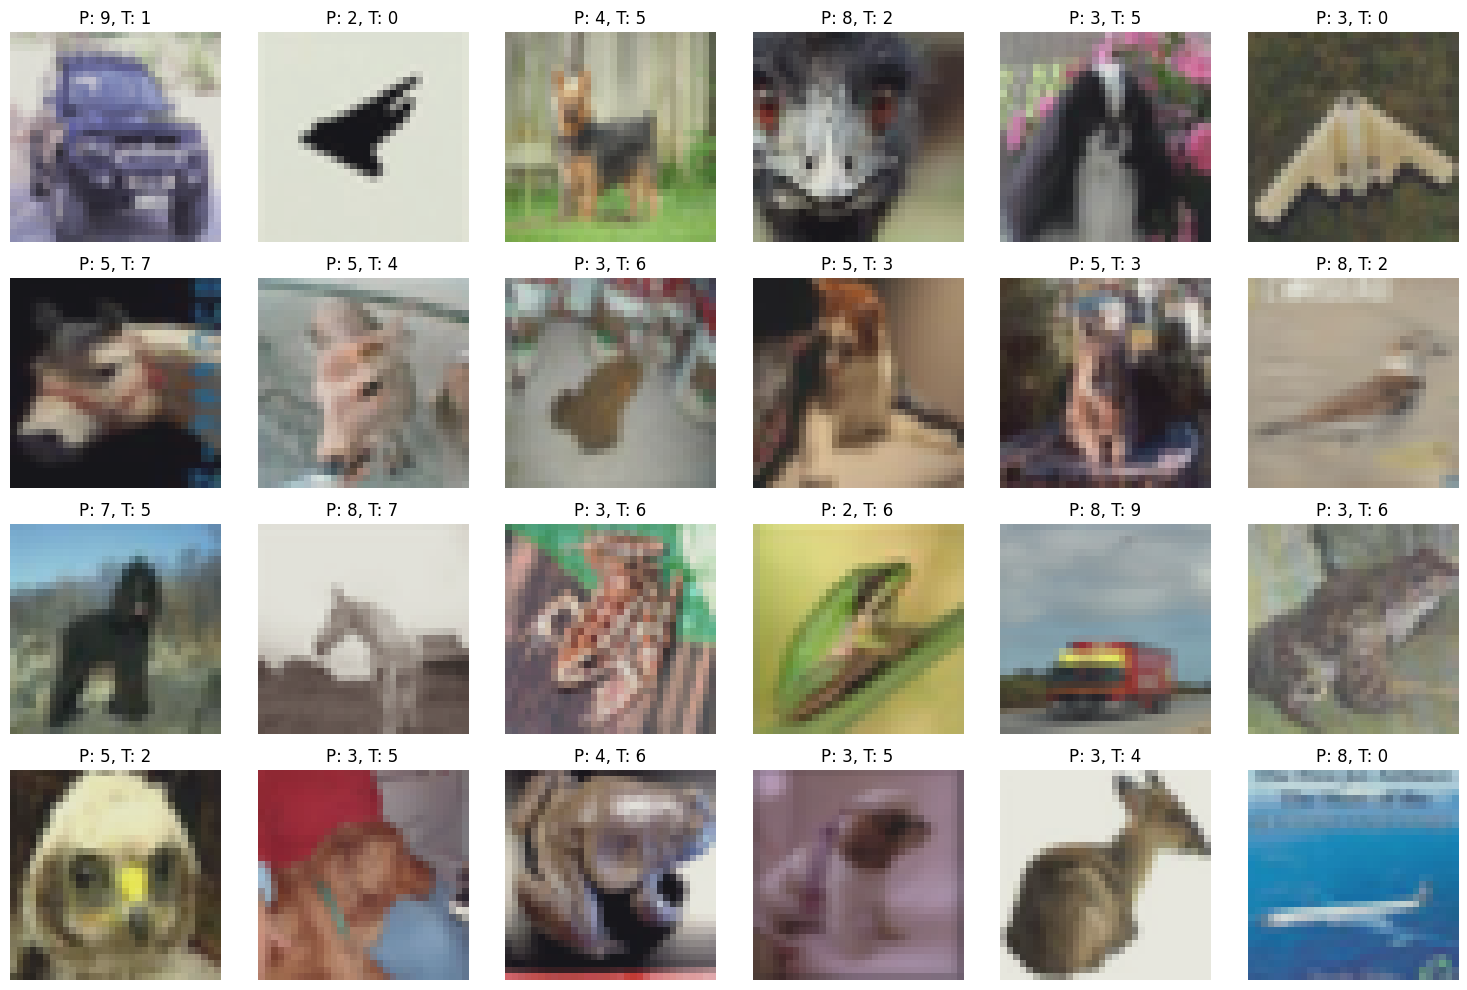

In [28]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import numpy as np
import random
def imshow(img, mean, std):
    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    plt.imshow(img)
def show_incorrect_samples(model, testloader, device, mean, std, num_images=24):
    model.eval()
    incorrect_images = []
    incorrect_preds = []
    incorrect_labels = []

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            wrong_indices = (preds != labels).nonzero(as_tuple=False).squeeze()

            for idx in wrong_indices:
                incorrect_images.append(inputs[idx].cpu())
                incorrect_preds.append(preds[idx].cpu().item())
                incorrect_labels.append(labels[idx].cpu().item())
                if len(incorrect_images) >= num_images:
                    break
            if len(incorrect_images) >= num_images:
                break
    plt.figure(figsize=(15, 10))
    for i in range(num_images):
        plt.subplot(4, 6, i+1)
        imshow(incorrect_images[i], mean, std)
        plt.title(f"P: {incorrect_preds[i]}, T: {incorrect_labels[i]}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.2023, 0.1994, 0.2010])
show_incorrect_samples(model, testloader, device, mean, std, num_images=24)


## Exploring the feature space

### Calculate the feature space for all training samples

You have trained and evaluated your model. Now, for each sample in the trainset, calculate it's "feature space" discussed in the model section. The result of this section should be a tensor of size `(45000, N)` saved in a variable (for later usage)

- **Hint:** Pay attension to the `shuffle` attribute of your train dataloader (If needed)

In [43]:
model.eval()
model.extract_features = True
trainloader_noshuffle = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=False)
features_list = []
with torch.no_grad():
    for inputs, _ in trainloader_noshuffle:
        inputs = inputs.to(device)
        _, features = model(inputs)
        features_list.append(features.cpu())
feature_space = torch.cat(features_list, dim=0)
print("Feature space shape:", feature_space.shape)


Feature space shape: torch.Size([45000, 1024])


### K Nearest Neighbor in feature space

We already have calculated the feature spaces for trainset ($S$) in the previous section. Now we follow these steps to explore the featre space:

1. Get 5 random samples from testset which are correctly predicted by the model.
2. for each sample, calculate it's "feature space" ($X$)
3. for each sample, calculate it's *5* nearest neighbors in "feature space" in the trainset (by comparing $X$ to each row in $S$) and visualize them

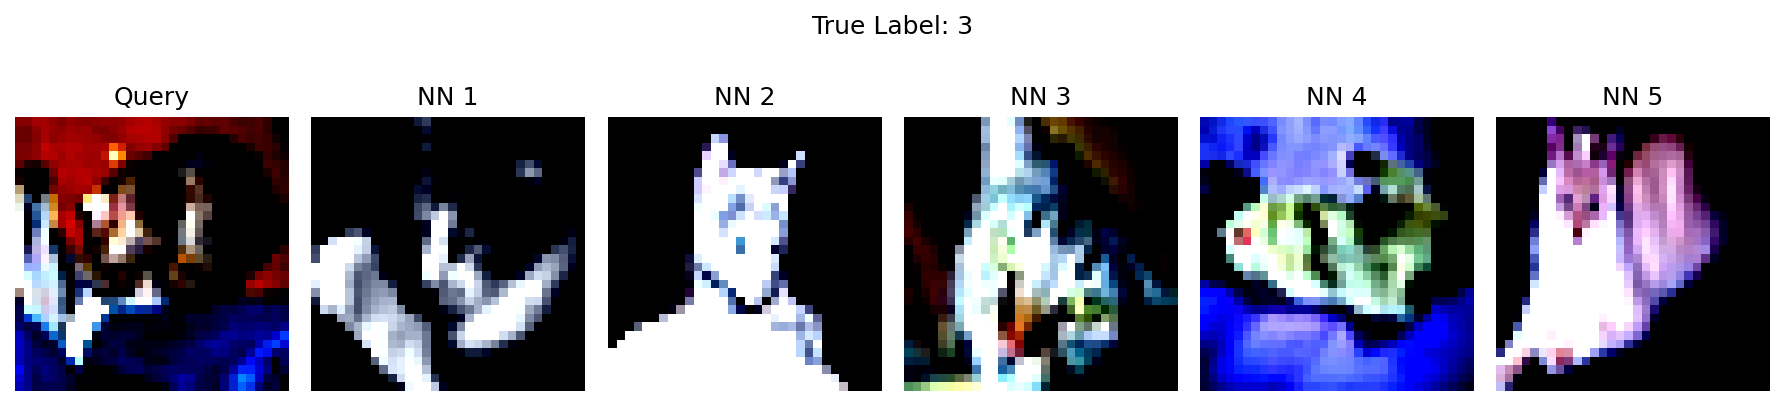

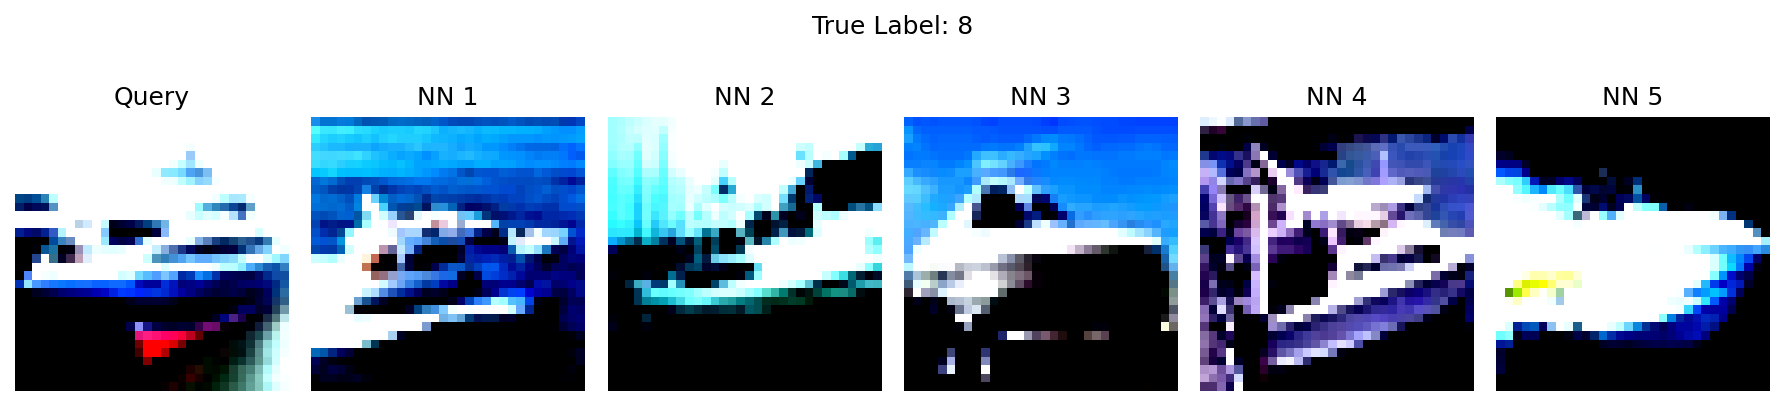

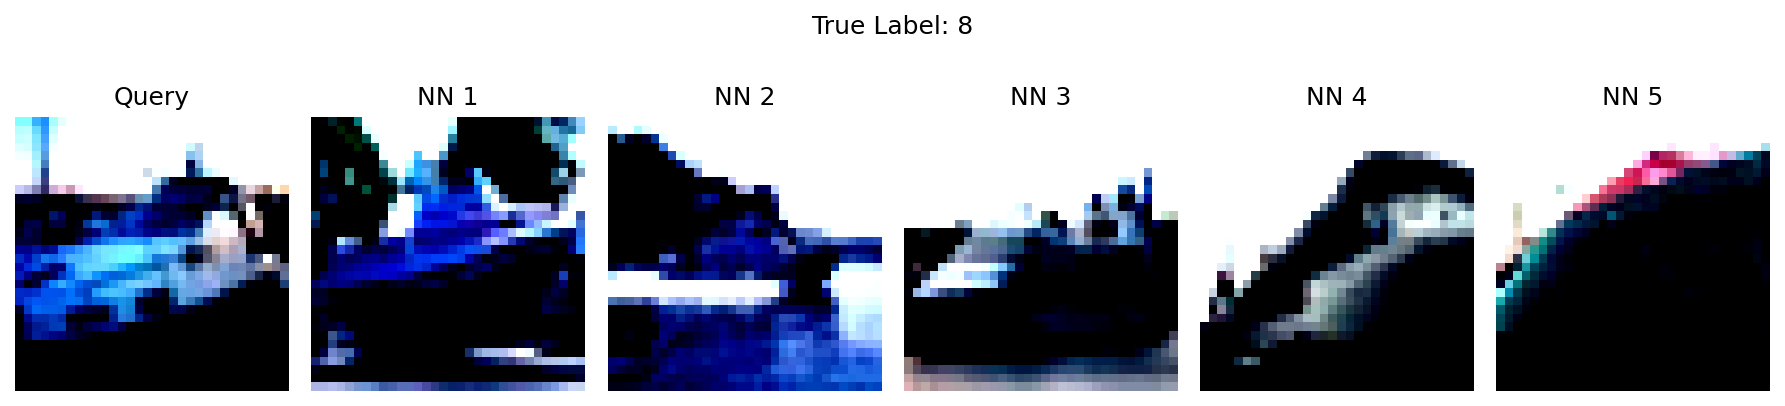

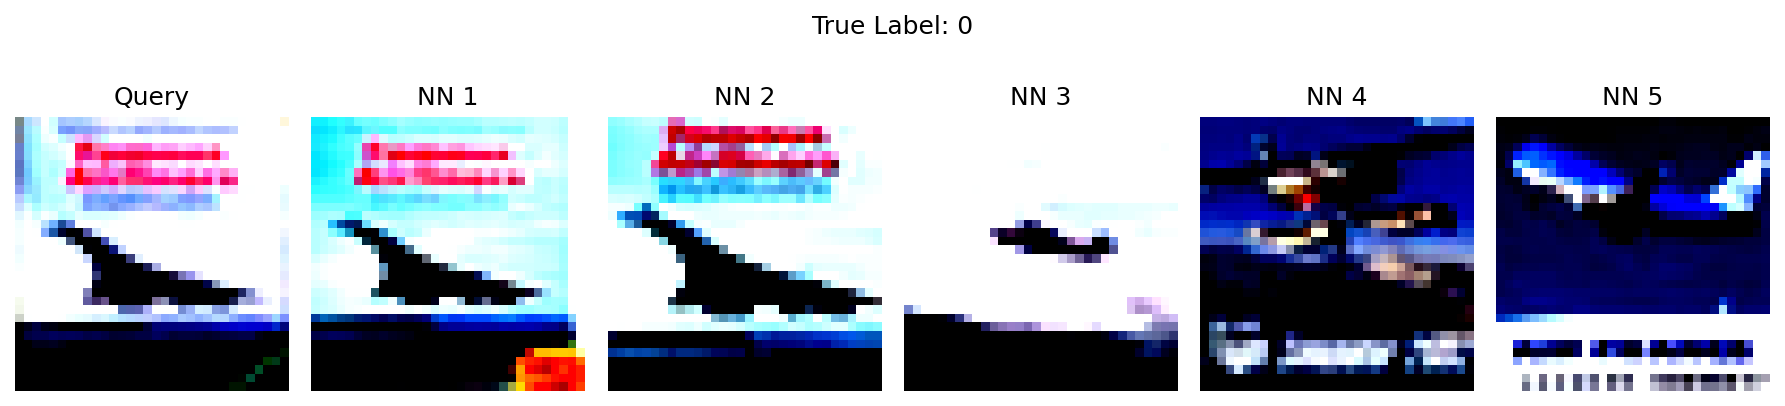

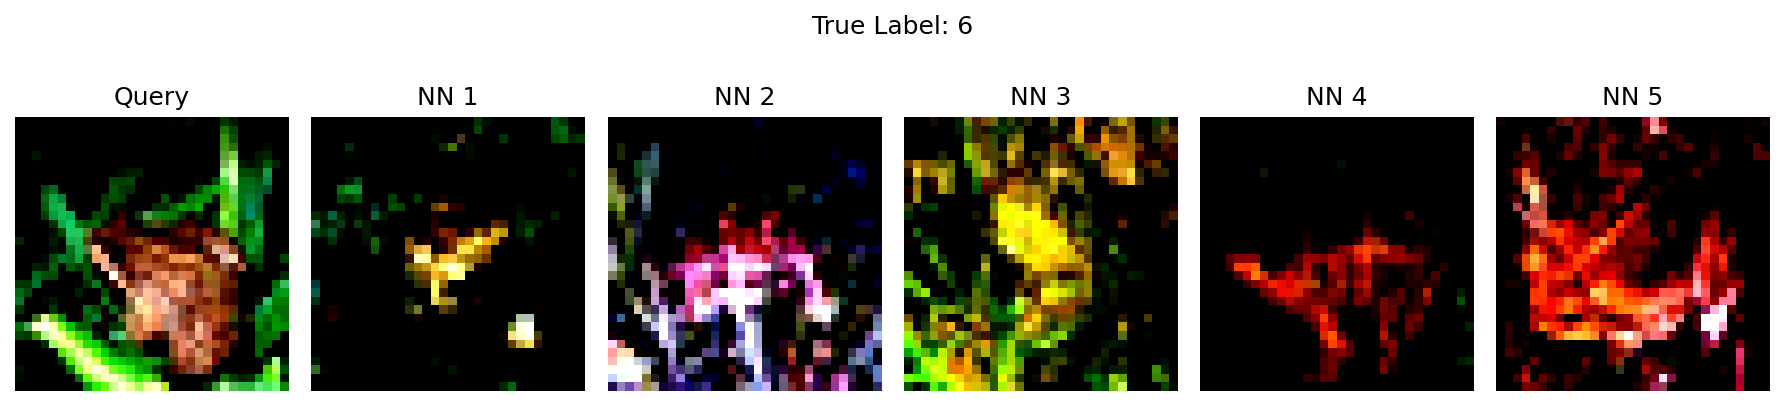

In [44]:
import matplotlib.pyplot as plt
import torch
model.eval()
model.extract_features = True
correct_samples = []
correct_labels = []
correct_features = []
correct_images = []
with torch.no_grad():
    for inputs, labels in testloader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs, features = model(inputs)
        preds = torch.argmax(outputs, dim=1)
        correct_mask = preds == labels
        for i in range(inputs.size(0)):
            if correct_mask[i]:
                correct_samples.append(inputs[i].cpu())
                correct_labels.append(labels[i].cpu())
                correct_features.append(features[i].cpu())
                if len(correct_samples) == 5:
                    break
        if len(correct_samples) == 5:
            break
correct_features = torch.stack(correct_features)
for idx in range(5):
    x = correct_features[idx].unsqueeze(0)
    distances = torch.norm(feature_space - x, dim=1)
    nearest_idxs = torch.topk(distances, 5, largest=False).indices
    fig, axes = plt.subplots(1, 6, figsize=(12, 3))
    axes[0].imshow(correct_samples[idx].permute(1, 2, 0))
    axes[0].set_title("Query")
    axes[0].axis('off')
    for i, neighbor_idx in enumerate(nearest_idxs):
        neighbor_img, _ = trainset[neighbor_idx]
        axes[i+1].imshow(neighbor_img.permute(1, 2, 0))
        axes[i+1].set_title(f"NN {i+1}")
        axes[i+1].axis('off')
    plt.suptitle(f"True Label: {correct_labels[idx].item()}")
    plt.tight_layout()
    plt.show()

model.extract_features = False


### TSNE

Let's follow these steps to explore feature space even more:

1. Sample $M$ ($2000$ would be enought) random samples from the trainset feature space (calculated in the above sections)
2. Now we have a vector of size `(M, N)` where $N$ is the dimension of the feature space
3. Using TSNE reduce $N$ to $2$ (Now we have a vector of size `(M, 2)`)
4. Visualize the points in a 2D plane (Set color of each point based on it's class)


In [31]:
from sklearn.manifold import TSNE

indices = np.random.randint(0, len(feature_space), 2000)
feature_space = feature_space[indices]
tsne = TSNE(n_components=2, random_state=42)
reduced_space = tsne.fit_transform(feature_space.reshape(feature_space.shape[0], -1).detach().cpu().numpy())

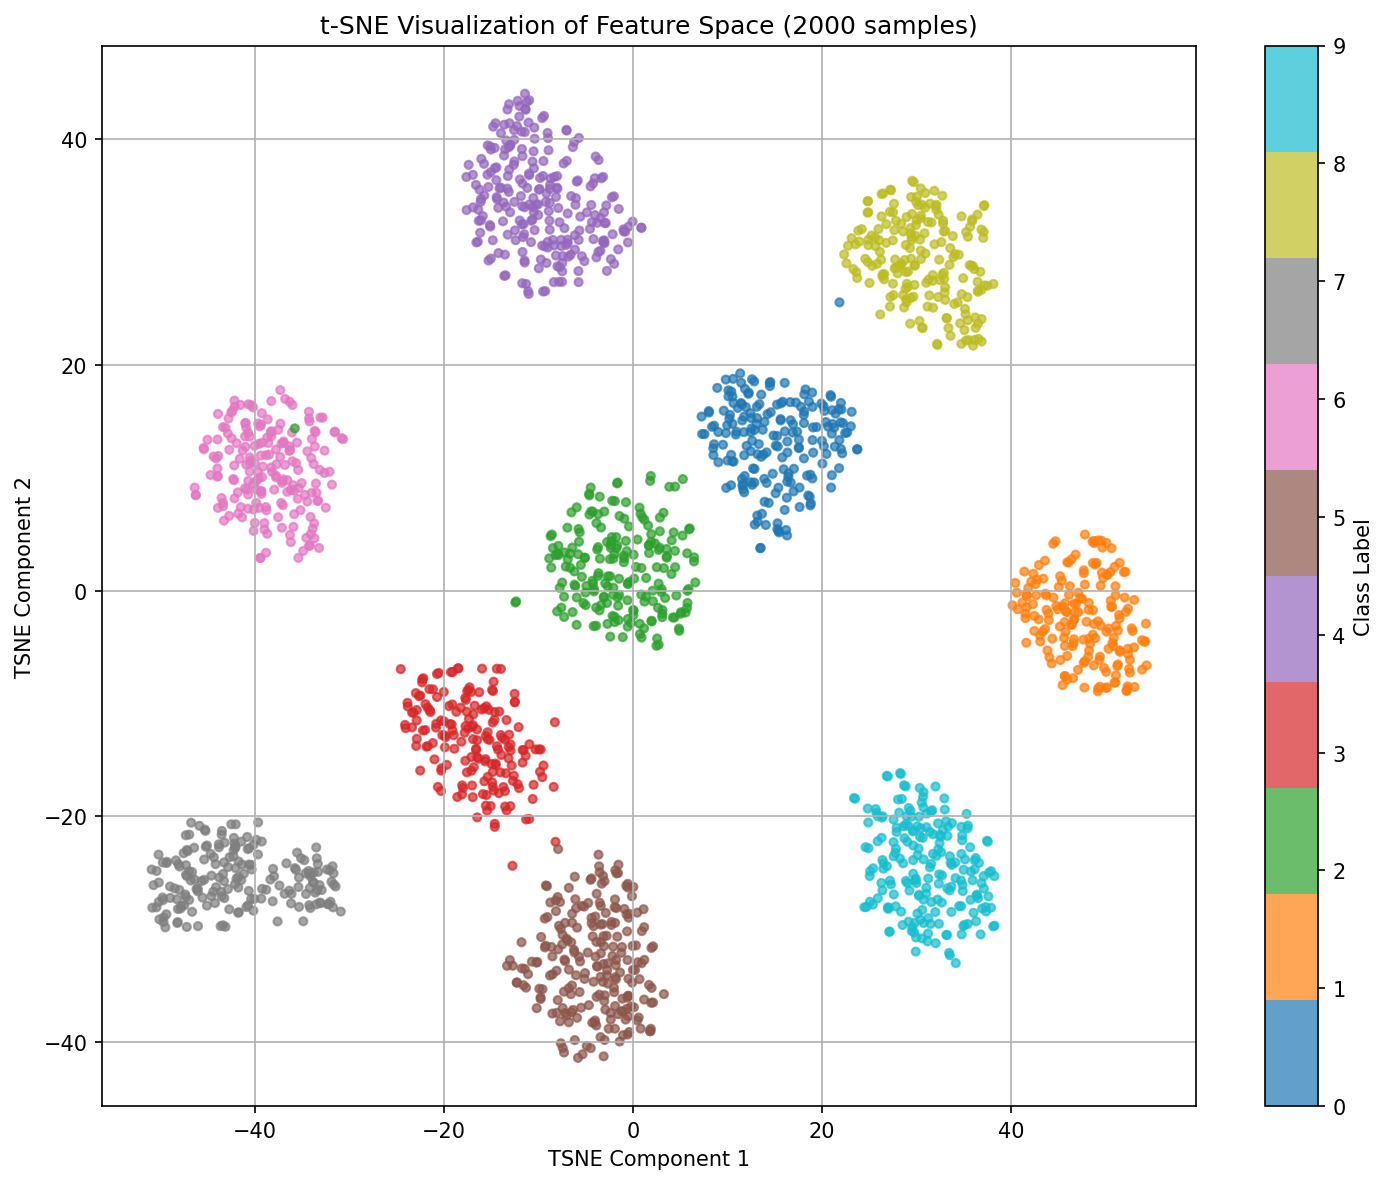

In [45]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
M = 2000
indices = np.random.choice(len(feature_space), M, replace=False)
subset_features = feature_space[indices]
all_targets = torch.tensor(trainset.dataset.targets)
subset_labels = all_targets[torch.tensor(trainset.indices)[indices]]
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca")
reduced_space = tsne.fit_transform(subset_features.numpy())
plt.figure(figsize=(10, 8))
scatter = plt.scatter(reduced_space[:, 0], reduced_space[:, 1], c=subset_labels, cmap='tab10', s=15, alpha=0.7)
plt.colorbar(scatter, ticks=range(10), label='Class Label')
plt.title("t-SNE Visualization of Feature Space (2000 samples)")
plt.xlabel("TSNE Component 1")
plt.ylabel("TSNE Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()


### Feature Map


In this part, we are going to visualize the output of one of the convolutional layers to see what features they focus on.

First, let's select a random image from dataset.

In [46]:
image = trainset[3][0]

Now, we are going to *clip* our model at different points to get different intermediate representation.
* Clip your model at least at one point and plot the filters output. You can use the output of first Resnet block.

In order to clip the model, you can use `model.children()` method. For example, to get output only after the first 2 layers, you can do:

```
clipped = nn.Sequential(
    *list(model.children()[:2])
)
intermediate_output = clipped(input)
```



CNN(
  (conv1): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=8192, out_features=3470, bias=True)
  (bn_fc1): BatchNorm1d(3470, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc2): Linear(in_features=3470, out_features=1024, bias=True)
  (bn_fc2): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc3): Linear(in_features=1024, out_features

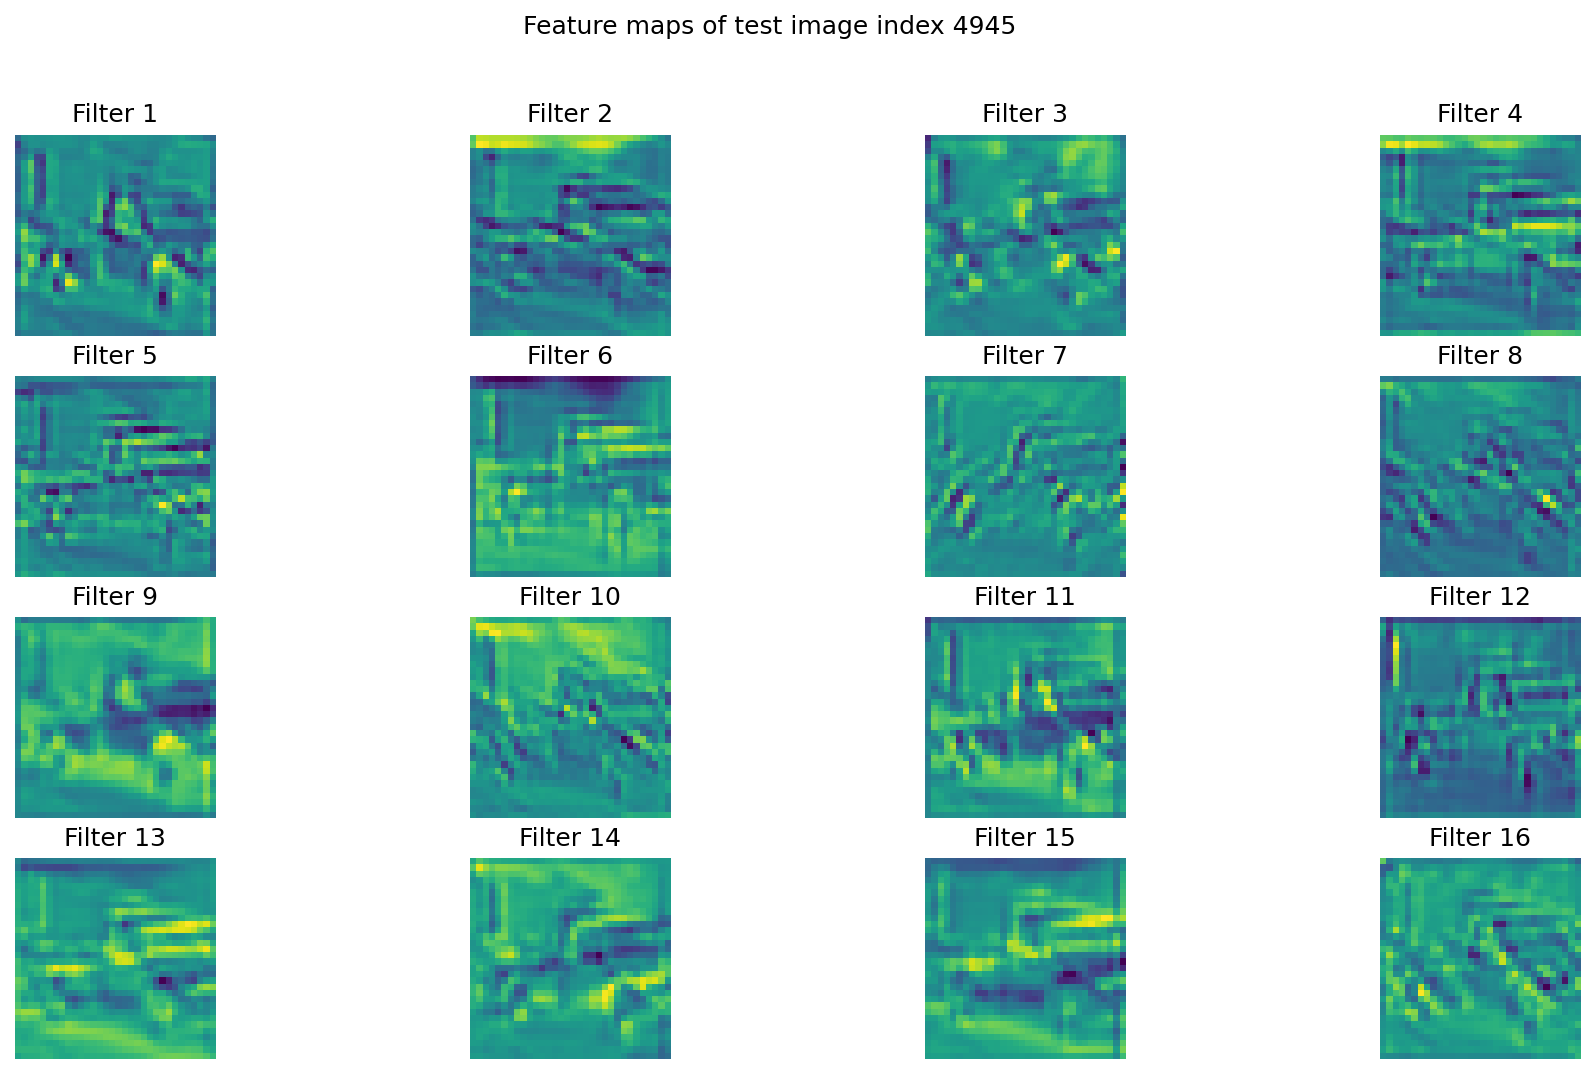

In [50]:
random_idx = random.randint(0, len(testset) - 1)
image, label = testset[random_idx]
input_tensor = image.unsqueeze(0).to(device)
print(model)
clipped_model = nn.Sequential(*list(model.children())[:4])
model.eval()
with torch.no_grad():
    intermediate_output = clipped_model(input_tensor)
output = intermediate_output.cpu().squeeze(0)
num_filters = min(16, output.shape[0])
plt.figure(figsize=(15, 8))
for i in range(num_filters):
    plt.subplot(4, 4, i + 1)
    plt.imshow(output[i], cmap='viridis')
    plt.axis('off')
    plt.title(f'Filter {i+1}')
plt.suptitle(f'Feature maps of test image index {random_idx}')
plt.show()


In [51]:
intermediate_output = None

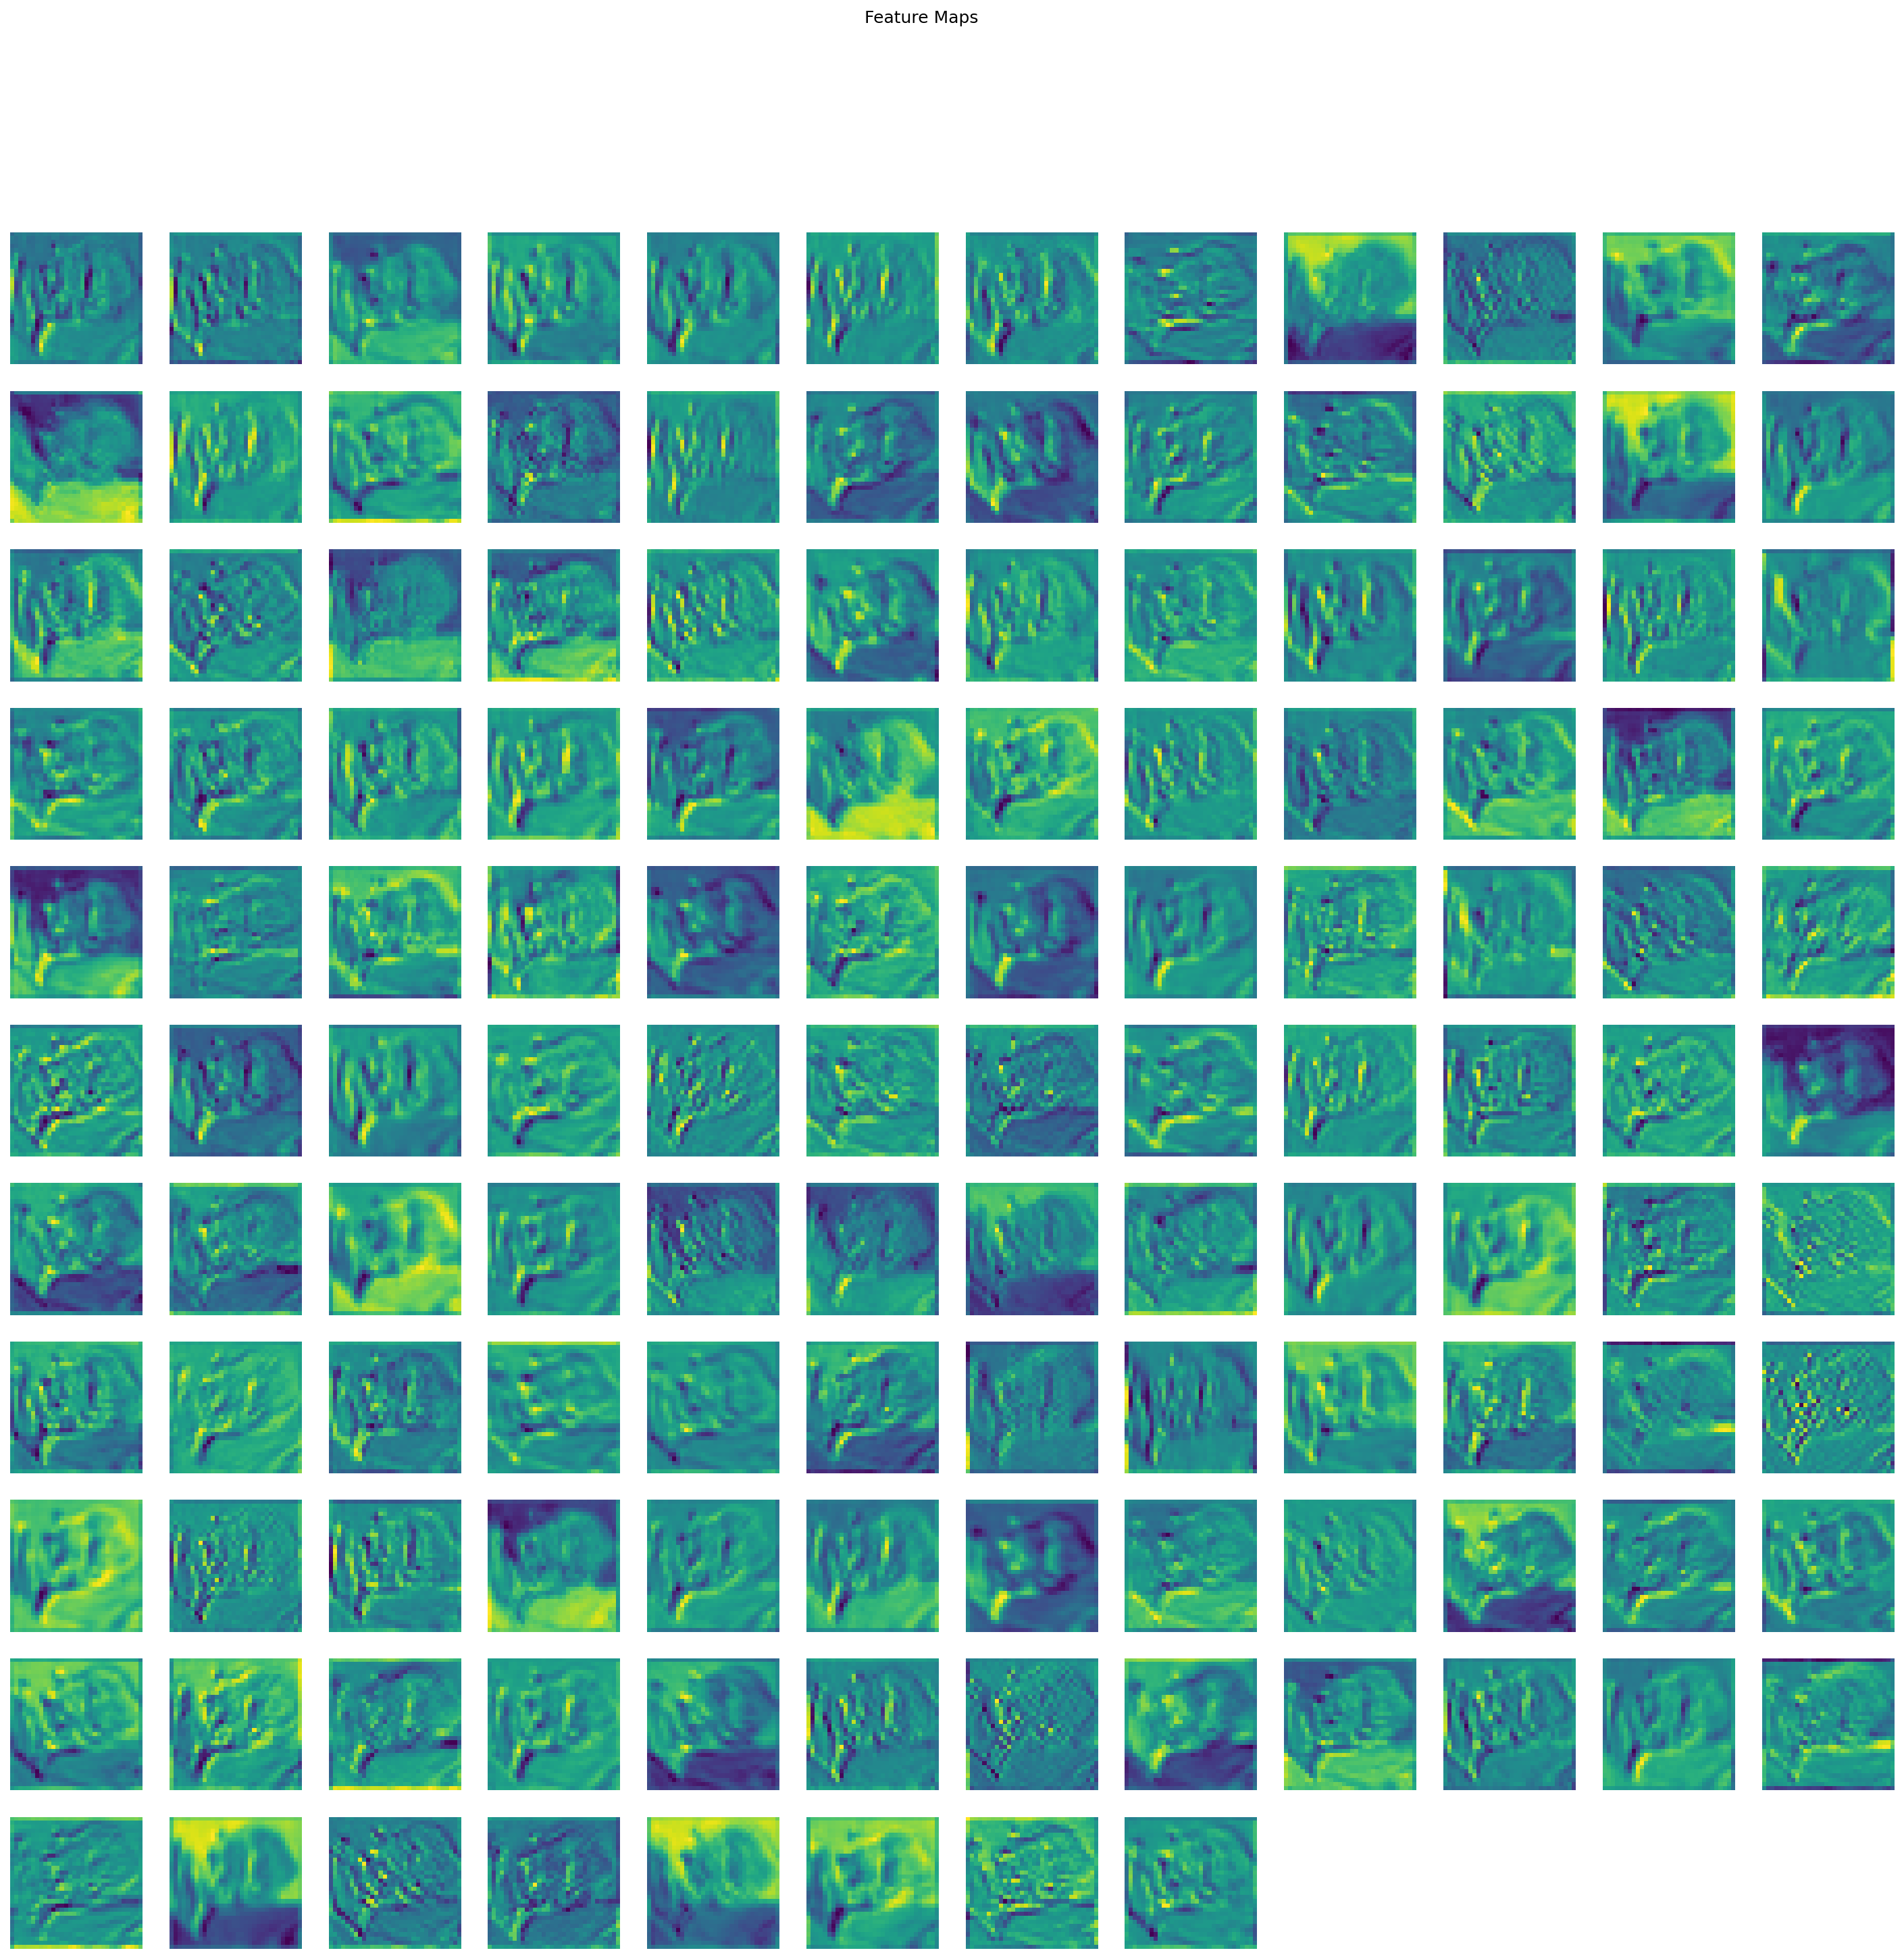

In [52]:
import math
import matplotlib.pyplot as plt
import torch

intermediate_output = None
def hook_fn(module, input, output):
    global intermediate_output
    intermediate_output = output
handle = model.conv1.register_forward_hook(hook_fn)
sample_inputs, _ = next(iter(testloader))
sample_inputs = sample_inputs.to(device)
model.eval()
with torch.no_grad():
    _ = model(sample_inputs)
handle.remove()
def plot_intermediate_output(result, title=None):
    plt.rcParams['figure.dpi'] = 150
    n_filters = result.shape[1]
    N = int(math.sqrt(n_filters))
    M = (n_filters + N - 1) // N
    assert N * M >= n_filters

    fig, axs = plt.subplots(N, M, figsize=(M*2, N*2))
    fig.suptitle(title)

    for i in range(N):
        for j in range(M):
            idx = i*M + j
            if idx < n_filters:
                axs[i][j].imshow(result[0, idx].cpu().detach(), cmap='viridis')
                axs[i][j].axis('off')
            else:
                axs[i][j].axis('off')

plot_intermediate_output(intermediate_output, title='Feature Maps')



**Note:** You are expected to analyze all results presented in this notebook and thoughtfully consider the underlying reasons behind them. Be prepared to discuss your insights during the **in-person review session**.
A written report is not required.


چرا سی ان ان بهتره؟

در سی ان ان، وزن‌های فیلترها در همه نقاط تصویر مشترک هستند که باعث کاهش پارامترها و افزایش کارایی می‌شود.

سی ان ان با استفاده از کانولوشن، ارتباطات محلی در تصویر را حفظ می‌کند (مثلاً لبه‌ها، شکل‌ها) در حالی که اف سی این ساختار را نادیده می‌گیرد.

با تعداد پارامتر کمتر، شبکه سریع‌تر و بهینه‌تر آموزش می‌یابد.

 سی ان ان خود به خود می‌تواند ویژگی‌های سطح پایین و سطح بالاتر تصویر را یاد بگیرد، در حالی که شبکه‌های اف سی نیاز به پیش‌پردازش یا انتخاب ویژگی دستی دارند.

شباهت ظاهری:
به این معنا که تصاویر از نظر بصری شبیه به هم هستند. مثلا یک تصویر سگ و تصویر سگ‌های مشابه در همسایگی‌شان.

شباهت معنایی:
یعنی تصاویر از نظر دسته‌بندی یا معنای محتوا (مثلاً همه سگ هستند، یا همه خودرو) به هم مرتبط‌اند، حتی اگر کمی ظاهرشان فرق کند.

ضای ویژگی استخراج شده توسط مدل سی ان ان نمایانگر ویژگی‌های مهم تصاویر است.

همسایگان نزدیک در این فضا تصاویر با ویژگی‌های مشابه (معمولاً معنایی) هستند.

نزدیکی در فضای ویژگی به خاطر یادگیری ویژگی‌های معنادار توسط مدل است نه فقط شباهت ظاهری ساده.

داده‌های آموزش و تست در این فضا به خوبی منطبق شده‌اند و مدل توانسته فضای ویژگی قابل تعمیم ایجاد کند.

ارتباط میان فضای ویژگی مدل و خوشه‌بندی داده‌ها:

مشاهده می‌کنیم که نمونه‌ها با برچسب‌های مشابه (یعنی از یک کلاس یا دسته) در فضای دوبعدی نزدیک هم و در قالب خوشه‌هایی جداگانه قرار دارند؛

این یعنی فضای ویژگی که مدل ساخته است، داده‌ها را به گونه‌ای نگاشت کرده که نمونه‌های هم‌کلاس (مثلاً همه تصاویر سگ یا همه تصاویر خودرو) در یک منطقه از فضای ویژگی تجمع دارند؛

علت این خوشه‌بندی، یادگیری ویژگی‌های مفید و معنادار توسط مدل سی ان ان است که به‌خوبی توانسته نمونه‌های هم‌کلاس را از هم متمایز کند؛

بنابراین، تی_اس به عنوان یک ابزار کاهش ابعاد غیرخطی ساختار این فضای ویژگی را به صورت بصری نشان می‌دهد و نشان می‌دهد که مدل فضای ویژگی قابل تمیز و تفکیک‌پذیری ساخته است.

فضای ویژگی مدل سی ان ان نمونه‌ها را بر اساس ویژگی‌های مشترکشان خوشه‌بندی کرده است.

این خوشه‌بندی نشان‌دهنده این است که مدل توانسته است نمایشی معنی‌دار از داده‌ها بیاموزد که داده‌های هم‌کلاس را نزدیک به هم قرار می‌دهد.

کاهش ابعاد با تی_اس ساختار خوشه‌ای فضای ویژگی را به شکل دوبعدی قابل مشاهده نمایش می‌دهد.

نقشه های ویژگی:

نقشه‌های ویژگی خروجی‌های هر لایه پیچشی در سی ان ان هستند که نشان‌دهنده پاسخ (فعالیت) هر فیلتر (کرنل) به بخش‌های مختلف تصویر ورودی می‌باشند؛

هر فیلتر در یک لایه پیچشی به دنبال ویژگی خاصی مثل لبه‌ها، گوشه‌ها، بافت‌ها یا الگوهای پیچیده‌تر در تصویر است؛

به همین دلیل، هر نقشه ویژگی یک ماتریس دوبعدی است که شدت فعالیت فیلتر را در هر ناحیه از تصویر نشان می‌دهد؛

کشف مناطق مهم تصویر و درک سلسله‌مراتب ویژگی‌ها و تشخیص اشکالات یا نقاط ضعف مدل و تفسیر و اعتماد به مدل